# Neural sentiment classifiers
## Dense network tuning
Select a Dense network using macro F1 on a stratified validation split. The model averages token embeddings before the hidden layer, so its predictions are insensitive to word order. The 200 test comments are reserved for final evaluation.

In [1]:
import sys
from pathlib import Path

root = Path.cwd()
if root.name == "notebooks":
    root = root.parent
sys.path.insert(0, str(root))

import numpy as np
from src.models import build_dense
from src.preprocessing import (
    MAX_LEN, SEED, build_vectorizer, load_splits, train_val_split,
    vectorize, vocabulary_size,
)
from src.train import BASE_GRID, grid_search, train_model
from src.visualize import plot_learning_curves

In [2]:
texts, labels, _, _ = load_splits()
texts_tr, texts_val, y_tr, y_val = train_val_split(texts, labels, seed=SEED)
vectorizer = build_vectorizer(texts_tr, max_len=MAX_LEN)
vocab_size = vocabulary_size(vectorizer)
X_tr = vectorize(vectorizer, texts_tr)
X_val = vectorize(vectorizer, texts_val)
assert X_tr.shape == (680, MAX_LEN) and X_val.shape == (120, MAX_LEN)
assert np.bincount(y_tr).tolist() == [340, 340]
assert np.bincount(y_val).tolist() == [60, 60]
print(f"Training: {len(y_tr)} | Validation: {len(y_val)} | Vocabulary: {vocab_size}")

Training: 680 | Validation: 120 | Vocabulary: 2138


### Grid and selection rule
Use the same split and seed for all 48 trials. Each trial restores the epoch with the lowest validation loss. Rank the restored models by validation macro F1 and break ties using validation loss. The table shows the five highest-ranked configurations.

In [3]:
dense_grid = grid_search(
    build_dense, BASE_GRID, X_tr, y_tr, X_val, y_val,
    vocab_size=vocab_size, epochs=30, seed=SEED,
)
assert len(dense_grid) == 48 and not dense_grid.duplicated(list(BASE_GRID)).any()
dense_grid.loc[:, [*BASE_GRID, "val_f1_macro", "val_accuracy", "best_val_loss", "best_epoch"]].head(5)

,embed_dim,units,dropout,lr,batch_size,val_f1_macro,val_accuracy,best_val_loss,best_epoch
0,32,32,0.5,0.003,32,0.758182,0.758333,0.554038,4
1,32,32,0.2,0.003,16,0.757913,0.758333,0.543800,2
2,32,32,0.2,0.003,32,0.749931,0.750000,0.540455,3
3,32,32,0.5,0.001,32,0.749722,0.750000,0.548143,8
4,32,32,0.5,0.001,16,0.749722,0.750000,0.550326,5


### Learning curves for the selected configuration
Repeat the winning trial with the same seed and plot training and validation loss and accuracy. The dotted line marks the epoch restored by early stopping.

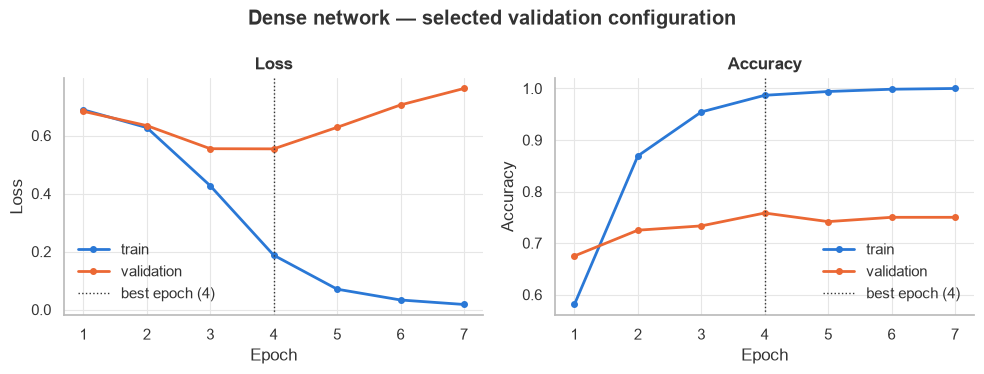

In [4]:
best = dense_grid.iloc[0]
dense_params = dict(
    vocab_size=vocab_size, max_len=MAX_LEN, embed_dim=int(best.embed_dim),
    units=int(best.units), dropout=float(best.dropout), lr=float(best.lr),
)
dense_history, _ = train_model(
    build_dense, dense_params, X_tr, y_tr, X_val, y_val,
    batch_size=int(best.batch_size), epochs=30, seed=SEED,
)
dense_fig = plot_learning_curves(
    dense_history, title="Dense network — selected validation configuration",
    name="03_dense_learning_curves",
)

In [5]:
hist = dense_history.history
epoch = int(np.argmin(hist["val_loss"]))
spread = best.val_f1_macro - dense_grid.iloc[4].val_f1_macro
print(f"Best validation macro F1: {best.val_f1_macro:.3f}. "
      f"Difference from fifth place: {spread:.3f}.")
print(f"At the refit's minimum validation loss (epoch {epoch + 1}), "
      f"training accuracy was {hist['accuracy'][epoch]:.1%} "
      f"and validation accuracy was {hist['val_accuracy'][epoch]:.1%}.")

Best validation macro F1: 0.758. Difference from fifth place: 0.008.
At the refit's minimum validation loss (epoch 4), training accuracy was 98.7% and validation accuracy was 75.8%.


## Vanilla RNN tuning
The SimpleRNN reads token embeddings in sequence and classifies each comment from its final hidden state. Use the same 48 configurations, training and validation split, seed and ranking rule as the Dense experiment.

In [6]:
from src.models import build_rnn

rnn_grid = grid_search(
    build_rnn, BASE_GRID, X_tr, y_tr, X_val, y_val,
    vocab_size=vocab_size, epochs=30, seed=SEED,
)
assert len(rnn_grid) == 48 and not rnn_grid.duplicated(list(BASE_GRID)).any()
rnn_grid.loc[:, [*BASE_GRID, "val_f1_macro", "val_accuracy", "best_val_loss", "best_epoch"]].head(5)

,embed_dim,units,dropout,lr,batch_size,val_f1_macro,val_accuracy,best_val_loss,best_epoch
0,32,64,0.5,0.001,16,0.628274,0.633333,0.684271,1
1,64,64,0.5,0.003,16,0.624765,0.625000,0.751739,3
2,64,32,0.2,0.003,32,0.615357,0.625000,0.670363,1
3,32,32,0.2,0.001,16,0.614955,0.616667,0.666775,2
4,32,32,0.5,0.001,16,0.607652,0.608333,0.666948,2


### Learning curves for the selected configuration
Repeat the winning trial with the same seed and plot training and validation loss and accuracy. The dotted line marks the epoch restored by early stopping.

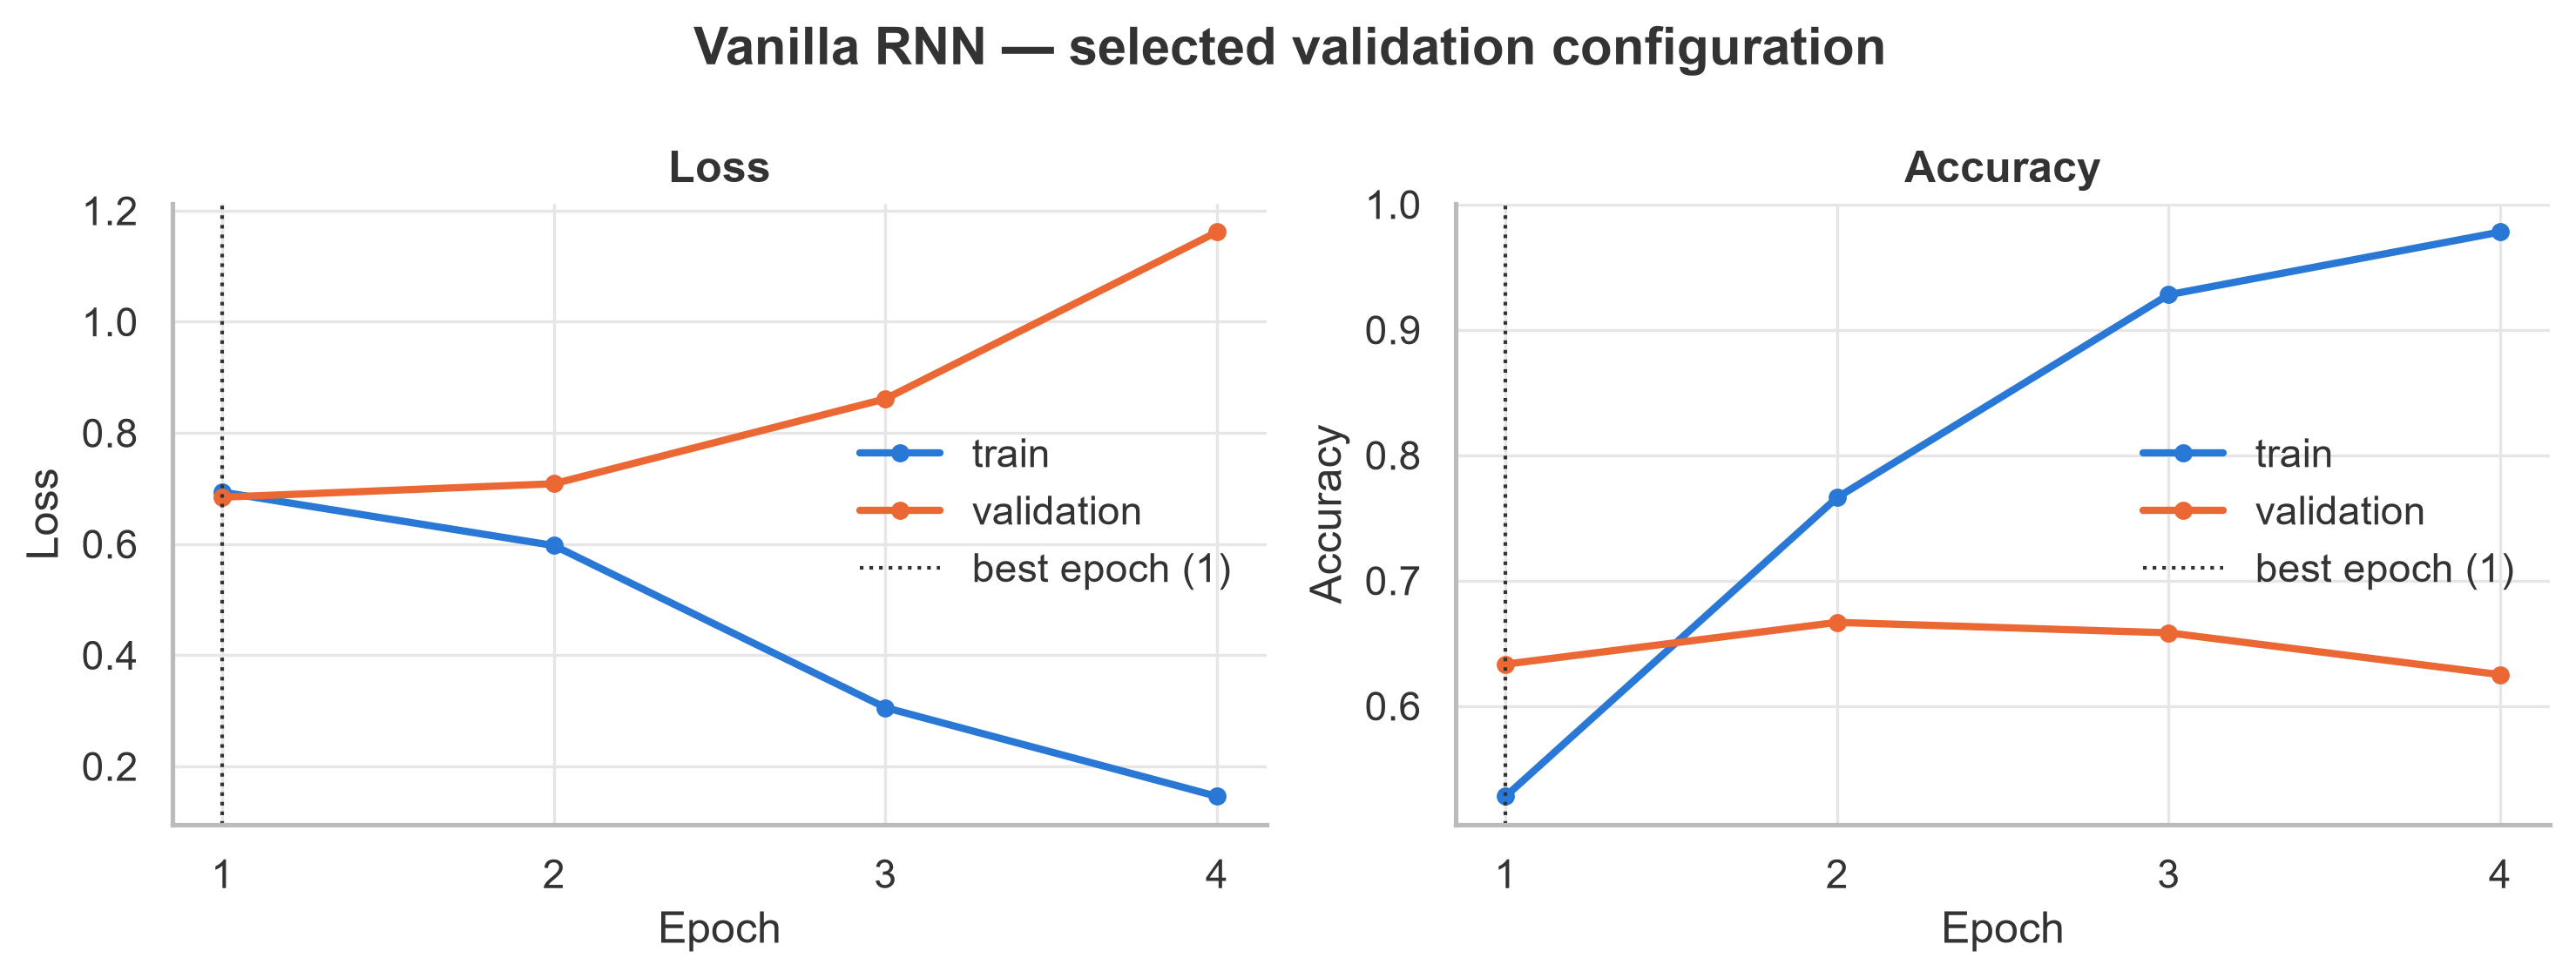

In [7]:
rnn_best = rnn_grid.iloc[0]
rnn_params = dict(
    vocab_size=vocab_size, max_len=MAX_LEN, embed_dim=int(rnn_best.embed_dim),
    units=int(rnn_best.units), dropout=float(rnn_best.dropout), lr=float(rnn_best.lr),
)
rnn_history, _ = train_model(
    build_rnn, rnn_params, X_tr, y_tr, X_val, y_val,
    batch_size=int(rnn_best.batch_size), epochs=30, seed=SEED,
)
rnn_fig = plot_learning_curves(
    rnn_history, title="Vanilla RNN — selected validation configuration",
    name="03_rnn_learning_curves",
)

In [8]:
hist = rnn_history.history
epoch = int(np.argmin(hist["val_loss"]))
spread = rnn_best.val_f1_macro - rnn_grid.iloc[4].val_f1_macro
print(f"Best validation macro F1: {rnn_best.val_f1_macro:.3f}. "
      f"Difference from fifth place: {spread:.3f}.")
print(f"At the refit's minimum validation loss (epoch {epoch + 1}), "
      f"training accuracy was {hist['accuracy'][epoch]:.1%} "
      f"and validation accuracy was {hist['val_accuracy'][epoch]:.1%}.")

Best validation macro F1: 0.628. Difference from fifth place: 0.021.
At the refit's minimum validation loss (epoch 1), training accuracy was 52.8% and validation accuracy was 63.3%.


The selected SimpleRNN scored 0.6283 macro F1 on validation, compared with 0.7582 for Dense on the same split. Its validation loss was lowest after the first epoch, so the three additional epochs did not improve the checkpoint. For this seed, processing tokens in order did not improve validation performance.

## LSTM tuning
The LSTM uses gates to control what it keeps or forgets as it reads the token sequence. Compare its 48 configurations on the same training and validation split, with seed 42 and the same ranking rule used for Dense and SimpleRNN.

In [9]:
from src.models import build_lstm

lstm_grid = grid_search(
    build_lstm, BASE_GRID, X_tr, y_tr, X_val, y_val,
    vocab_size=vocab_size, epochs=30, seed=SEED,
)
assert len(lstm_grid) == 48 and not lstm_grid.duplicated(list(BASE_GRID)).any()
lstm_grid.loc[:, [*BASE_GRID, "val_f1_macro", "val_accuracy", "best_val_loss", "best_epoch"]].head(5)

,embed_dim,units,dropout,lr,batch_size,val_f1_macro,val_accuracy,best_val_loss,best_epoch
0,64,32,0.5,0.003,32,0.733037,0.733333,0.580022,2
1,32,64,0.2,0.003,32,0.724828,0.725000,0.558476,2
2,32,16,0.5,0.001,32,0.724522,0.725000,0.556235,5
3,32,16,0.5,0.003,32,0.721734,0.725000,0.591292,2
4,32,16,0.2,0.001,32,0.715957,0.716667,0.557308,5


### Learning curves for the selected configuration
Repeat the winning trial with the same seed and plot training and validation loss and accuracy. The dotted line marks the epoch restored by early stopping.

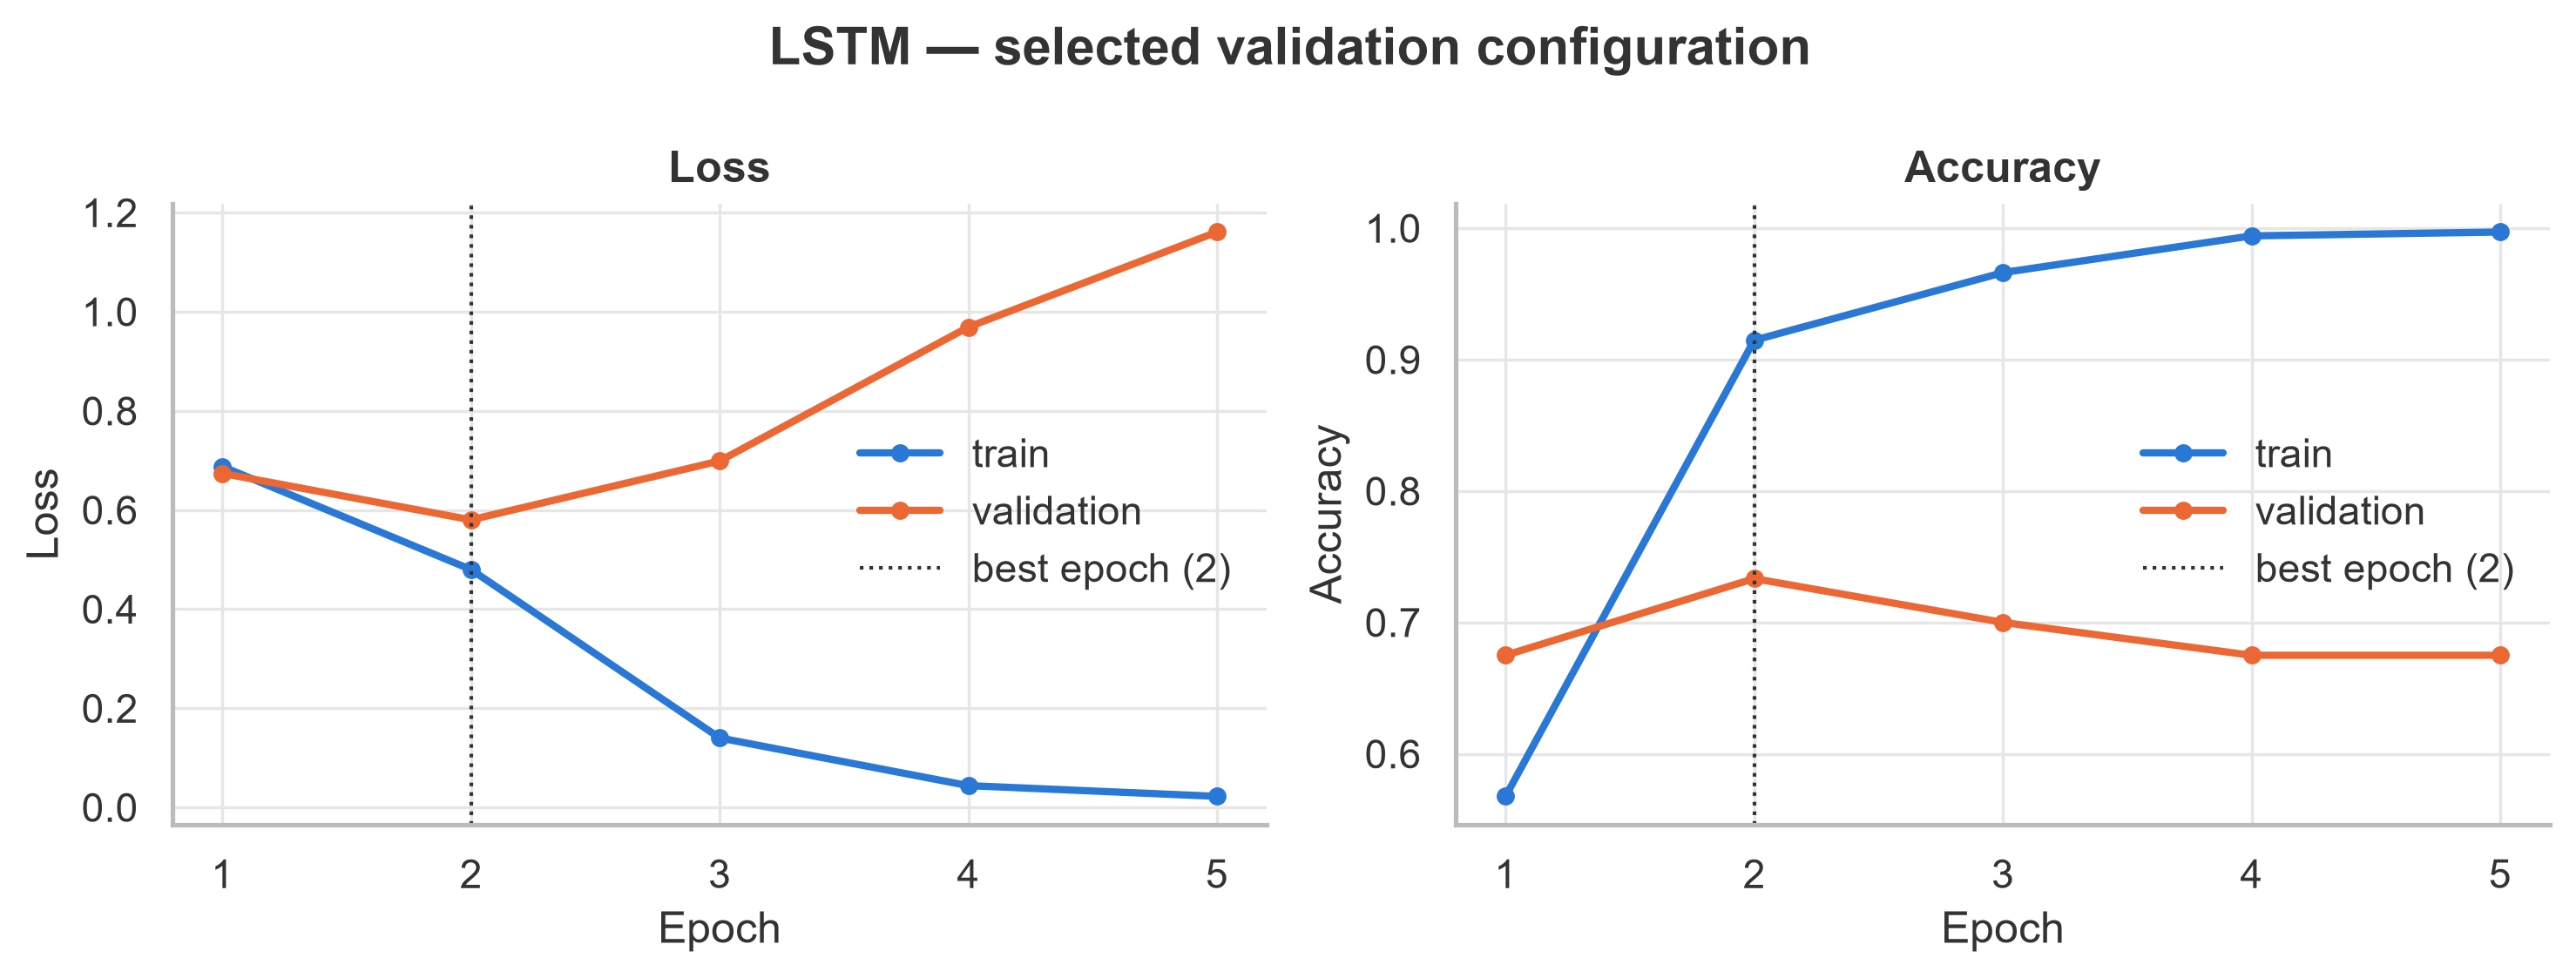

In [10]:
lstm_best = lstm_grid.iloc[0]
lstm_params = dict(
    vocab_size=vocab_size, max_len=MAX_LEN, embed_dim=int(lstm_best.embed_dim),
    units=int(lstm_best.units), dropout=float(lstm_best.dropout), lr=float(lstm_best.lr),
)
lstm_history, _ = train_model(
    build_lstm, lstm_params, X_tr, y_tr, X_val, y_val,
    batch_size=int(lstm_best.batch_size), epochs=30, seed=SEED,
)
lstm_fig = plot_learning_curves(
    lstm_history, title="LSTM — selected validation configuration",
    name="03_lstm_learning_curves",
)

In [11]:
hist = lstm_history.history
epoch = int(np.argmin(hist["val_loss"]))
spread = lstm_best.val_f1_macro - lstm_grid.iloc[4].val_f1_macro
print(f"Best validation macro F1: {lstm_best.val_f1_macro:.3f}. "
      f"Difference from fifth place: {spread:.3f}.")
print(f"At the refit's minimum validation loss (epoch {epoch + 1}), "
      f"training accuracy was {hist['accuracy'][epoch]:.1%} "
      f"and validation accuracy was {hist['val_accuracy'][epoch]:.1%}.")

Best validation macro F1: 0.733. Difference from fifth place: 0.017.
At the refit's minimum validation loss (epoch 2), training accuracy was 91.5% and validation accuracy was 73.3%.


The best LSTM used 64-dimensional embeddings, 32 recurrent units, dropout 0.5, learning rate 0.003 and batch size 32. On the same 120 validation comments and seed 42, its macro F1 was 0.7330, above SimpleRNN (0.6283) and below Dense (0.7582). The winning refit reached its minimum validation loss (0.5800) at epoch 2 and stopped after epoch 5. At epoch 2 training accuracy was 91.5% while validation accuracy was 73.3%, an 18.2 percentage point gap.